In [3]:
from matplotlib.ticker import FuncFormatter

# Polski format liczb
def comma_formatter(x, pos):
    return f'{x:g}'.replace('.', ',')

formatter = FuncFormatter(comma_formatter)

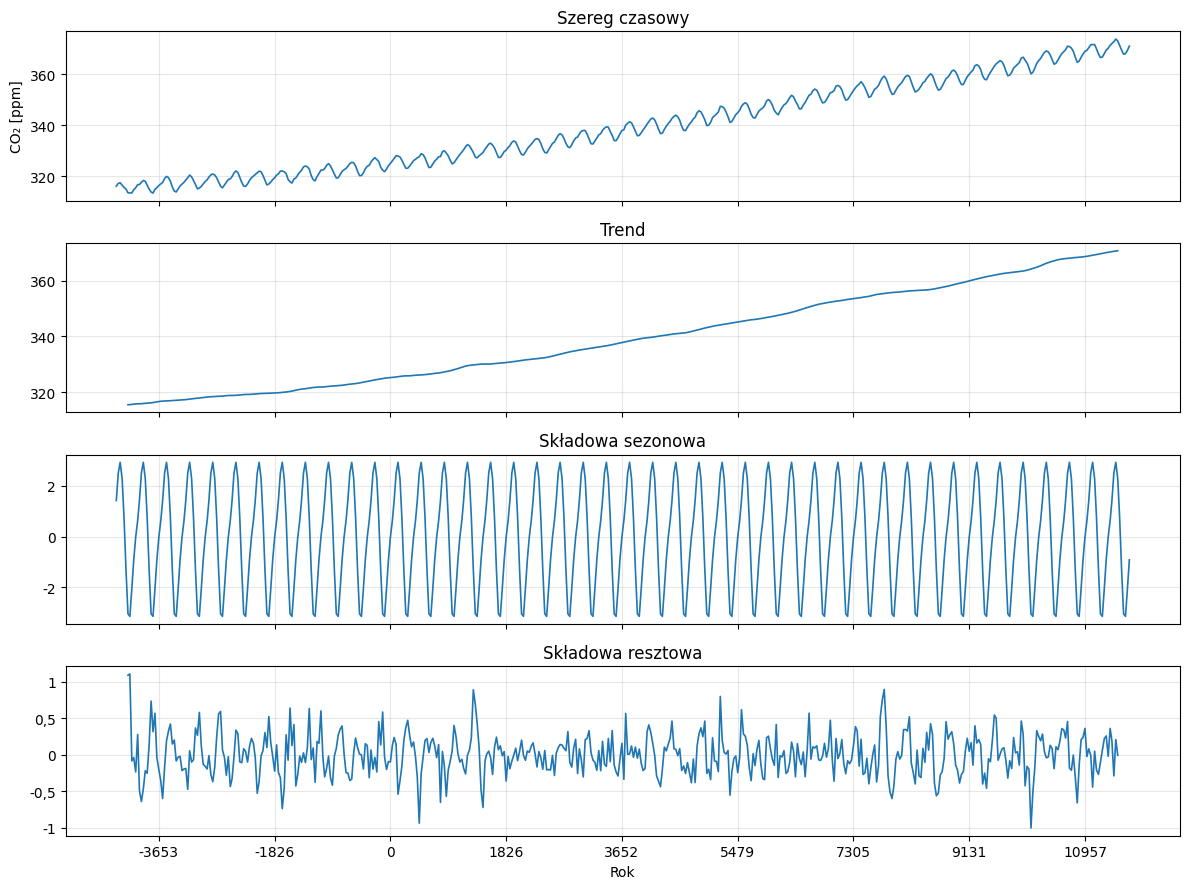

In [4]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose

# Wczytanie rzeczywistych danych
data = sm.datasets.co2.load_pandas().data

# Agregacja do częstotliwości miesięcznej
series = data['co2'].resample('MS').mean().interpolate()

# Dekompozycja addytywna
decomposition = seasonal_decompose(
    series,
    model='additive',
    period=12
)

# Wizualizacja
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

components = [
    (series, 'Szereg czasowy'),
    (decomposition.trend, 'Trend'),
    (decomposition.seasonal, 'Składowa sezonowa'),
    (decomposition.resid, 'Składowa resztowa')
]

for ax, (values, title) in zip(axes, components):
    ax.plot(values.index, values, linewidth=1.2)
    ax.set_title(title, fontsize=12)
    ax.grid(alpha=0.25)
    
for ax in axes:
    ax.xaxis.set_major_formatter(formatter)
    ax.yaxis.set_major_formatter(formatter)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('CO₂ [ppm]')
axes[-1].set_xlabel('Rok')

plt.tight_layout()
plt.savefig('dekompozycja_co2.png', dpi=300, bbox_inches='tight')
plt.show()